# Pipeline de limpieza y visualización
- Autor: Mauricio Montes
- Fecha: 13 jul 2025

## Sobre el dataset
Estoy un poco familiarizado con este dataset para trabajar un proyecto de la universidad, que consiste en varios (decenas de miles) vuelos y el precio de estos. El objetivo original del dataset es practicar la implementación de un modelo predictivo con regresión lineal, pero, ajá, será para este proyecto ahora.

Este es el enlace: [Kaggle: Flight Price Prediction](https://www.kaggle.com/datasets/shubhambathwal/flight-price-prediction/data)

Se utilizará el dataset limpio (`Clean_Dataset.csv`), el cual debería ser fácil de depurar; renombrado a `flight-price.csv`.

## Instalación de dependencias
Los paquetes utilizados son los que se muestran en la celda de abajo. En caso de no tenerlos instalados, descomentar la celda.

In [ ]:
# En caso de que el entorno virtual no tenga el kernel de python.
# !pip install ipykernel 

# Instalación de paquetes
# !pip install numpy pandas matplotlib seaborn


[notice] A new release of pip is available: 24.3.1 -> 25.1.1
[notice] To update, run: pip install --upgrade pip


Ahora, se importan los paquetes instalados para poder usarlos.

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

## Análisis exploratorio del Dataset
A continuación se extrae el dataset en un DataFrame de `pandas`; y se realiza un análisis exploratorio.

In [4]:
df = pd.read_csv("flight-price.csv")
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [5]:
df.tail()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [7]:
df.describe()

,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [8]:
df.describe(include="object")

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class
count,300153,300153,300153,300153,300153,300153,300153,300153
unique,6,1561,6,6,3,6,6,2
top,Vistara,UK-706,Delhi,Morning,one,Night,Mumbai,Economy
freq,127859,3235,61343,71146,250863,91538,59097,206666


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.shape

(300153, 12)

Del análisis exploratorio podemos concluir que el dataset está muy limpio. No hay datos duplicados ni valores nulos. Sin embargo, es un dataset muy grande, de alrededor de 300k registros de vuelos (sé que en la gran escala de las cosas, no es tan grande, pero hasta ahora es uno de los más grandes que he visto).

En cuanto a las columnas categóricas:
- `airline` consiste en 6 diferentes aerolíneas.
- `flight` es el código del vuelo. Si bien son 300k registros, serán solo de los tickets para el vuelo, no el vuelo en sí.
- `source_city` y `destination_city` son las ciudades en las que operan los vuelos. Solo hay 6 ciudades.
- `departure_time` y `arrival_time` es más o menos el tiempo en que salen y llegan los vuelos. No usan horas exactas, solo si es de madrugada, mañana, tarde, noche, por ejemplo.
- `stops` describe la cantidad de paradas que tendrá un vuelo.
- `class` el tipo de asiento dentro del vuelo. Si es clase `business` o `economy`.

De lo que se puede ver, hay una columna que estorba: `Unnamed: 0`. Por otro lado, las columnas numéricas, puedo determinar que:
- La columna `duration` se refiere a la **cantidad de horas** que durará un viaje.
- La columna `days_left` hace referencia la cantidad de días que hace falta para que el viaje ocurra.
- La columna `price` es el costo del viaje... Pero no puedo determinar el tipo de moneda que representan.

In [11]:
df['destination_city'].unique()

array(['Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai', 'Delhi'],
      dtype=object)

En base a las ciudades de destino, se puede asumir que la unidad monetaria del precio son las rupias indias.

## Preparación del dataset

In [12]:
# Esto es más por costumbre que otra cosa. El dataset realmente está limpio, ahorrándome tiempo.
df.drop_duplicates(); 
df.dropna(); 

In [13]:
# Nos deshacemos de columnas innecesarias
df.drop(columns='Unnamed: 0', inplace=True)
df.describe()

,duration,days_left,price
count,300153.000000,300153.000000,300153.000000
mean,12.221021,26.004751,20889.660523
std,7.191997,13.561004,22697.767366
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4783.000000
50%,11.250000,26.000000,7425.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,123071.000000


In [14]:
# Probablemente también innecesario
df.drop(columns='flight', inplace=True); 
df.describe(include='object')

,airline,source_city,departure_time,stops,arrival_time,destination_city,class
count,300153,300153,300153,300153,300153,300153,300153
unique,6,6,6,3,6,6,2
top,Vistara,Delhi,Morning,one,Night,Mumbai,Economy
freq,127859,61343,71146,250863,91538,59097,206666


## Variables categóricas vs precio
Quiero saber cómo las variables categóricas afectan al precio las aerolíneas, la cantidad de paradas, etc.
No creo que la hora de salida o de llegada signifiquen algo; pues ese dato puede ser explicado por la variable numérica `duración`; igualmente por la ciudad de salida o de llegada, considerando que los viajes pueden tener paradas, por lo que lo más directo sería analizar `stops`.

### Clase vs precio

In [15]:
df.groupby('class')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
Business,93487.0,52540.081124,12969.314606,12000.0,45185.0,53164.0,60396.0,123071.0
Economy,206666.0,6572.342383,3743.519517,1105.0,4173.0,5772.0,7746.0,42349.0


La clase `economy` representa alrededor de 2/3 del dataset, con el tercio restante siendo la clase `business`. Aún así, podemos ver que la media de la clase `business` es casi **10 veces** mayor que la media de la clase `economy`. Eso significa que la clase tiene un impacto evidente en el precio; pues incluso el valor mínimo de `business` es el doble de la media de la clase `economy`.

### Aerolínea vs precio

In [16]:
df.groupby('airline')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
airline,,,,,,,,
AirAsia,16098.0,4091.072742,2824.055172,1105.0,2361.0,3276.0,4589.0,31917.0
Air_India,80892.0,23507.019112,20905.116909,1526.0,5623.0,11520.0,45693.0,90970.0
GO_FIRST,23173.0,5652.007595,2513.865560,1105.0,4205.0,5336.0,6324.0,32803.0
Indigo,43120.0,5324.216303,3268.894831,1105.0,3219.0,4453.0,6489.0,31952.0
SpiceJet,9011.0,6179.278881,2999.630406,1106.0,4197.0,5654.0,7412.0,34158.0
Vistara,127859.0,30396.536302,25637.159445,1714.0,6412.0,15543.0,55377.0,123071.0


La media del precio por las aerolíneas es interesante, pues parece haber que hay dos aerolíneas que tienen una media 5 a 6 veces mayor que el resto; sin embargo, estas tienen desviaciones estándar muy elevadas. La suma de los tickets de estas aerolíneas (`Air_India` y `Vistara`) representan alrededor de 188k de las 300k del dataset también, por lo que es difícil determinar si estas realmente tienen un impacto significativo en el precio.

### Paradas vs precio

In [17]:
df.groupby('stops')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
stops,,,,,,,,
one,250863.0,22900.992482,23626.066584,1105.0,5136.0,7959.0,48851.0,123071.0
two_or_more,13286.0,14113.450775,17664.332033,1966.0,6432.0,8307.0,13419.0,117307.0
zero,36004.0,9375.938535,10623.008293,1105.0,2586.0,4499.0,8064.0,59573.0


En el caso de la cantidad de paradas que tiene que hacer un vuelo, es difícil ver si influye en los precios signficativamente. Las medias son diferentes, sí; pero todos tienen elevadas desviaciones estándar. Aunque, a juzgar por los máximos y mínimos, parece ser que el precio es mayor cuando hay una parada y menor para un viaje directo.

In [18]:
df[df['class'] == 'Economy'].groupby('stops')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
stops,,,,,,,,
one,166561.0,6812.857800,3658.418081,1105.0,4416.0,5937.0,7950.0,42349.0
two_or_more,12203.0,9142.264279,4704.906533,1966.0,6089.0,8012.0,12160.5,35145.0
zero,27902.0,4012.624615,2106.398792,1105.0,2353.0,3531.0,4856.0,21058.0


In [19]:
df[df['class'] == 'Business'].groupby('stops')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
stops,,,,,,,,
one,84302.0,54687.377156,10622.569936,20000.0,48289.0,54608.0,60508.0,123071.0
two_or_more,1083.0,70127.660203,12739.907274,12000.0,64387.0,68743.0,76684.0,117307.0
zero,8102.0,27846.339052,6780.408368,12000.0,22152.0,27864.0,32859.0,59573.0


Tras verificar cómo varía el costo separando el dataset por la clase del viaje, el patrón se repite. Esta separación se hizo para determinar si el impacto de la clase del viaje es tan fuerte que afecta al análisis estadístico de esta variable.

## Variables numéricas vs precio
Estas puede que tenga una influencia más directa. Cómo expliqué en el caso de las variables categóricas, la duración de un viaje puede influir mucho en su costo; al igual que la cantidad de días que faltan para el viaje.
- Es posible que entre más tiempo tenga que pasar para un viaje, más barato sea.
- Es posible que entre más tiempo dure un viaje, este sea más caro.

### Duración vs precio

<Axes: xlabel='duration', ylabel='price'>

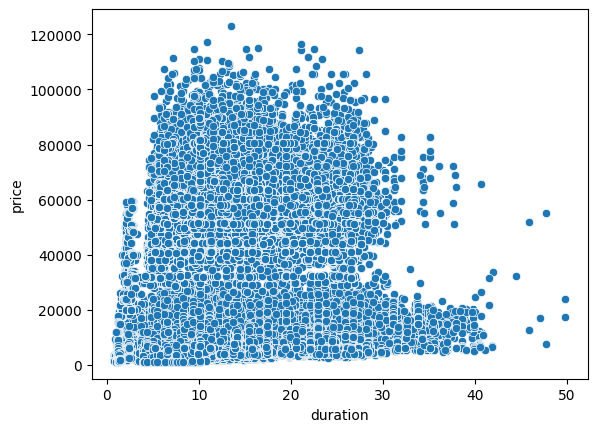

In [20]:
sns.scatterplot(x=df['duration'], y=df['price'])

No parece haber una correlación entre duración de un viaje y su precio; aunque puede que comparar todos los viajes no sea buena idea dado que los precios varían mucho dependiendo de la clase a la que pertenezcan. Entonces, separamos el dataframe por las clases de vuelo.

In [21]:
df_economy = df[df['class'] == 'Economy']
df_business = df[df['class'] != 'Economy']

<Axes: xlabel='duration', ylabel='price'>

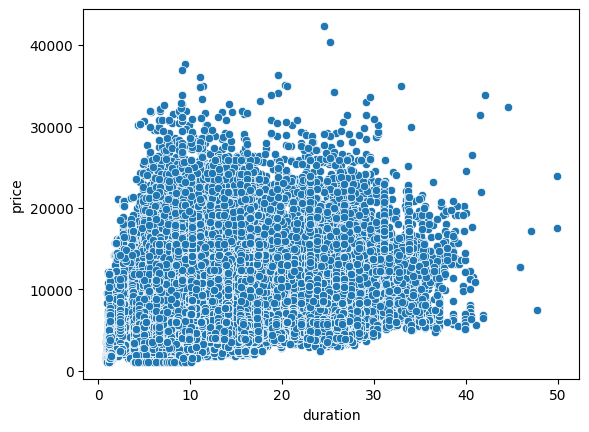

In [22]:
sns.scatterplot(x=df_economy['duration'], y=df_economy['price'])

<Axes: xlabel='duration', ylabel='price'>

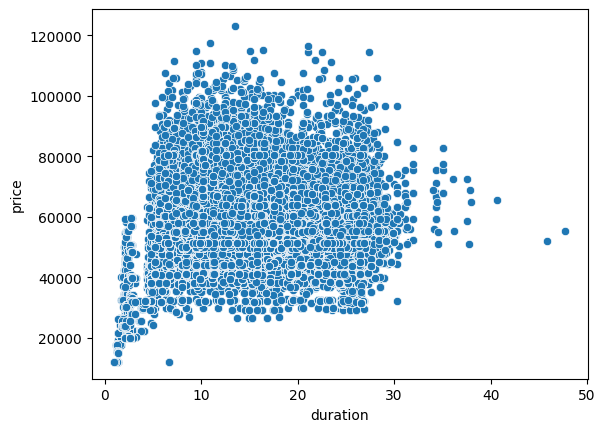

In [23]:
sns.scatterplot(x=df_business['duration'], y=df_business['price'])

Si bien los datos siguen siendo muy dispersos, hay un patrón que se puede ver abajo, y es que la duración del vuelo sí afecta al precio. Entre mayor es la duración, mayor es el precio en general; aunque también influirán el resto de las variables, cómo la aerolínea o cantidad de paradas.

In [24]:
economy_correlation = df_economy[['duration', 'price']].corr(method='pearson').iloc[0, 1]
business_correlation = df_business[['duration', 'price']].corr(method='pearson').iloc[0, 1]
print('Correlación entre precio y duración:'
      + f'\nEconomy: {economy_correlation:.2f}'
      + f'\nBusiness: {business_correlation:.2f}')

Correlación entre precio y duración:
Economy: 0.29
Business: 0.24


Aunque la correlación es más o menos visible en el mapa de dispersión... El coeficiente de correlación de Pearson parece indicar que la relación tiende más a lo aleatorio entre la duración y el precio. Es decir, el resto de las variables parece tener mayor significancia que la duración.

### Días restantes vs precio

Vamos a evaluar con los dataframes separados por clase, ya que se observó que trabajar con estos unidos afecta mucho a la visualización de la correlación.

<Axes: xlabel='days_left', ylabel='price'>

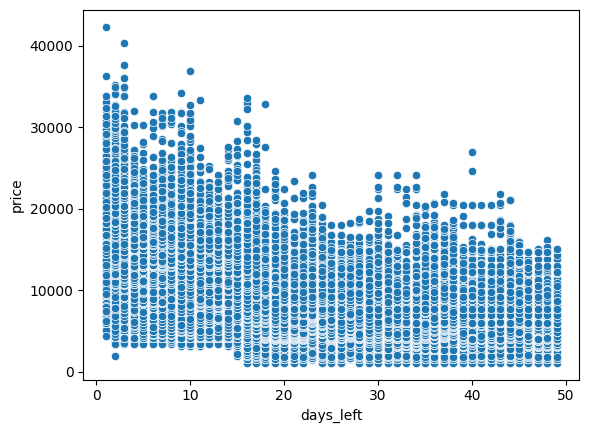

In [25]:
sns.scatterplot(x=df_economy['days_left'], y=df_economy['price'])

<Axes: xlabel='days_left', ylabel='price'>

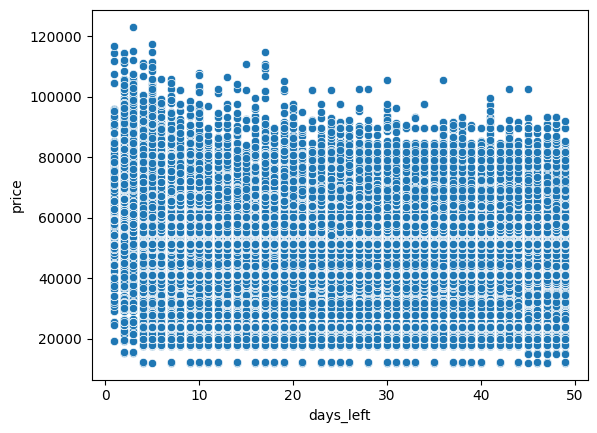

In [26]:
sns.scatterplot(x=df_business['days_left'], y=df_business['price'])

Observando los mapas de dispersión, parece ser que en los vuelos económicos, la cantidad de días restantes para el vuelo tiene mayor influencia que para los vuelos en clase Business: Si faltan más días, menor es el precio.

In [27]:
economy_correlation = df_economy[['days_left','price']].corr(method='pearson').iloc[0, 1]
business_correlation = df_business[['days_left','price']].corr(method='pearson').iloc[0, 1]
print(f'Correlación días restantes vs precio:'
      + f'\nEconomy: {economy_correlation:.2f}'
      + f'\nBusiness: {business_correlation:.2f}')

Correlación días restantes vs precio:
Economy: -0.56
Business: -0.09


Vemos el coeficiente de correlación para la clase económica es significativa pero no alta, con -0.56 (es decreciente) de correlación. Sin embargo, para la clase Business, esta parece ser casi aleatoria, con una correlación de -0.09.

## Nuevo cálculo, precio por rutas.
Puede que la ruta sí afecte al precio, es decir, saber de dónde a dónde es un viaje. Es por eso que se crea una nueva columna.

In [28]:
df['route'] = df['source_city'] + ' to ' + df['destination_city']
df['route'].describe()

count              300153
unique                 30
top       Delhi to Mumbai
freq                15289
Name: route, dtype: object

In [29]:
df.groupby('route')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
route,,,,,,,,
Bangalore to Chennai,6410.0,23321.850078,22573.185689,1603.0,4792.00,9241.0,44280.0,90720.0
Bangalore to Delhi,13756.0,17723.313972,19746.484106,2723.0,4111.00,7164.0,32923.0,111883.0
Bangalore to Hyderabad,8928.0,21226.121192,21886.188883,1694.0,5322.00,7813.0,37985.0,83239.0
Bangalore to Kolkata,10028.0,23500.061229,24631.108723,3026.0,5178.00,8112.0,51817.0,105168.0
Bangalore to Mumbai,12939.0,23128.618672,25887.684502,2150.0,5177.00,7113.0,54684.0,103819.0
Chennai to Bangalore,6493.0,25081.850454,23405.422526,1443.0,4755.00,10469.0,44144.0,107597.0
Chennai to Delhi,9783.0,18981.863948,21946.879653,2051.0,4179.00,7352.0,27792.0,103683.0
Chennai to Hyderabad,6103.0,21591.345404,22866.927328,1105.0,4202.00,7373.0,41064.0,92752.0
Chennai to Kolkata,6983.0,22669.932407,23667.149966,2359.0,5095.00,8394.0,54896.0,104624.0


Puede que hayan dos variables que afecten al cálculo de estas: La clase del viaje y la cantidad de paradas. Primero, separamos el dataset por la clase, y luego analizaremos de acuerdo a las paradas.

In [30]:
df_economy = df[df['class'] == 'Economy']
df_business = df[df['class'] != 'Economy']

In [31]:
economy_price_comparison = df.groupby(['route', 'stops'])['price'].agg(['mean', 'std', 'count'])
economy_price_comparison.sort_values(by='mean')

,,mean,std,count
route,stops,,,
Chennai to Bangalore,zero,2101.504444,1156.785961,450
Bangalore to Chennai,zero,2329.608333,1160.510476,480
Chennai to Hyderabad,zero,2660.925094,2187.424224,534
Hyderabad to Chennai,zero,2677.586792,2062.982844,530
Bangalore to Hyderabad,zero,3041.762557,2326.567757,876
...,...,...,...,...
Kolkata to Bangalore,one,25766.472948,25209.343978,8225
Bangalore to Mumbai,one,25806.215613,26949.693885,11029
Mumbai to Bangalore,one,26007.913003,27124.974725,10805


Son demasiadas columnas como para observar un patrón, por lo que segmentamos de acuerdo a la cantidad de palabras... Una tabla por cada cantidad.

In [32]:
zero_stops_economy = df[df['stops'] == 'zero'].groupby('route')['price'].agg(['mean', 'std', 'count'])
zero_stops_economy.sort_values(by='mean')

,mean,std,count
route,,,
Chennai to Bangalore,2101.504444,1156.785961,450
Bangalore to Chennai,2329.608333,1160.510476,480
Chennai to Hyderabad,2660.925094,2187.424224,534
Hyderabad to Chennai,2677.586792,2062.982844,530
Bangalore to Hyderabad,3041.762557,2326.567757,876
Hyderabad to Bangalore,3076.138272,2500.932388,810
Bangalore to Kolkata,4775.904192,3986.041523,668
Chennai to Kolkata,5792.919662,5119.245110,473
Hyderabad to Kolkata,6026.870707,5210.396355,495


In [33]:
one_stops_economy = df[df['stops'] == 'one'].groupby('route')['price'].agg(['mean', 'std', 'count'])
one_stops_economy.sort_values(by='mean')

,mean,std,count
route,,,
Hyderabad to Delhi,18663.704500,19538.034754,7066
Delhi to Hyderabad,18840.406380,19597.178081,7712
Bangalore to Delhi,18854.887192,20806.191144,11329
Delhi to Bangalore,19216.867785,21084.691737,11330
Chennai to Delhi,20096.839382,22902.768649,8349
Delhi to Chennai,20273.372308,22615.680454,8313
Mumbai to Delhi,21284.063088,20607.436063,11159
Kolkata to Delhi,21336.157072,24098.530362,8633
Hyderabad to Mumbai,21541.694025,23426.127135,9004


In [34]:
two_or_more_stops_economy = df[df['stops'] == 'two_or_more'].groupby('route')['price'].agg(['mean', 'std', 'count'])
two_or_more_stops_economy.sort_values(by='mean')

,mean,std,count
route,,,
Bangalore to Delhi,4514.856481,3368.925587,216
Kolkata to Delhi,5992.870722,5570.163473,263
Hyderabad to Delhi,6132.000000,0.000000,32
Mumbai to Delhi,7195.815385,2697.779845,65
Chennai to Hyderabad,7393.614213,3673.209725,591
Hyderabad to Mumbai,7912.800000,2684.731262,305
Delhi to Mumbai,8045.739726,3164.353765,73
Kolkata to Bangalore,8095.525215,3001.676795,813
Delhi to Bangalore,8181.837449,8196.709168,486


Observando solo la clase económica, es posible visualizar que hay un patrón; pero no está relacionado con las rutas; sino más bien con la cantidad de paradas que tiene el viaje. No parecen haber rutas que mantengan consistentemente su posición. Si bien esta comparación solo se ha hecho en la clase económica; sospecho que será el mismo resultado hacerlo con la clase económica.

## Visualización de datos

### Mapa de calor
Vamos a realizar un mapa de calor para observar la correlación entre variables numéricas. Observando que la clase afecta a la correlación, creo que el mapa de calor también tiene que tener esa distinción.

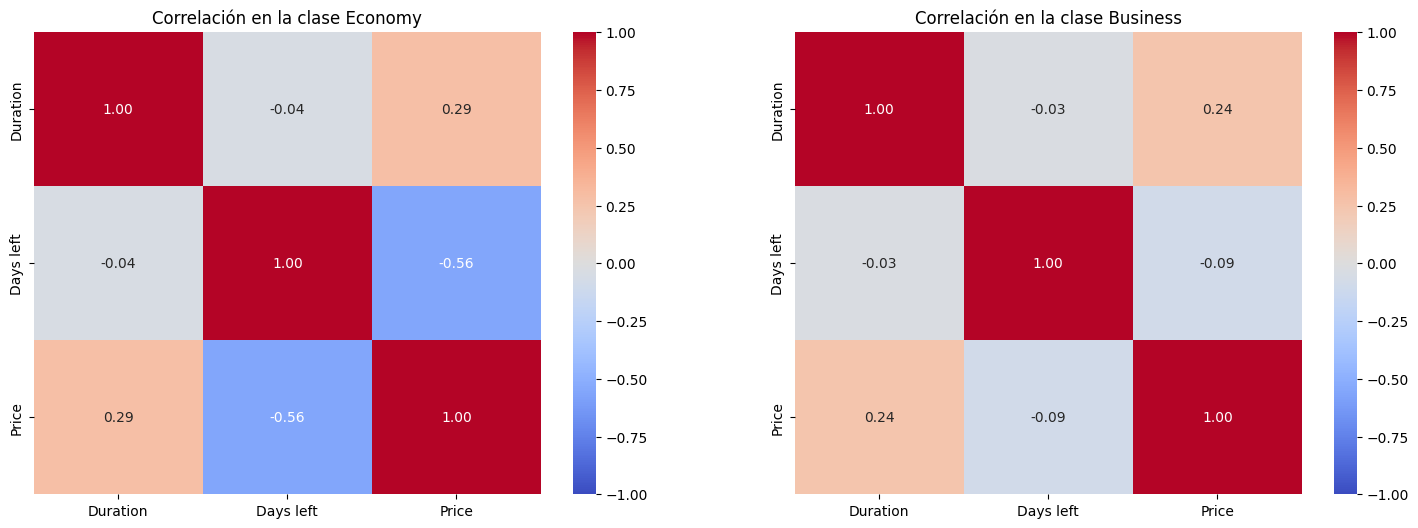

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

df.rename(columns={'days_left':'Days left', 'duration':'Duration', 'price':'Price'}, inplace=True)

df_economy = df[df['class'] == 'Economy']
df_business = df[df['class'] != 'Economy']

corr_economy = df_economy[['Duration', 'Days left', 'Price']].corr(method='pearson')
corr_business = df_business[['Duration', 'Days left', 'Price']].corr(method='pearson')

sns.heatmap(
    data=corr_economy,
    annot=True, fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    ax=axes[0]
)
axes[0].set_title('Correlación en la clase Economy')

sns.heatmap(
    data=corr_business,
    annot=True, fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    ax=axes[1]
)
axes[1].set_title('Correlación en la clase Business')

plt.plot()

# Para exportar el mapa de calor
# plt.savefig("heatmap.png")

Las zonas donde la correlación es igual a 1 no son relevantes en esta ocasión, pues es la correlación entre la misma variable (siempre será 1). Observando la correlación, observamos que realmente no parece haber una relación entre la cantidad de días restantes y la duración de un vuelo; pero parece haber una correlación entre el precio y la duración de un vuelo...

Otra gráfica que puedo hacer es un gráfico de barras, sobre el precio promedio por aerolínea; segregado por la clase (jaja, clasismo).

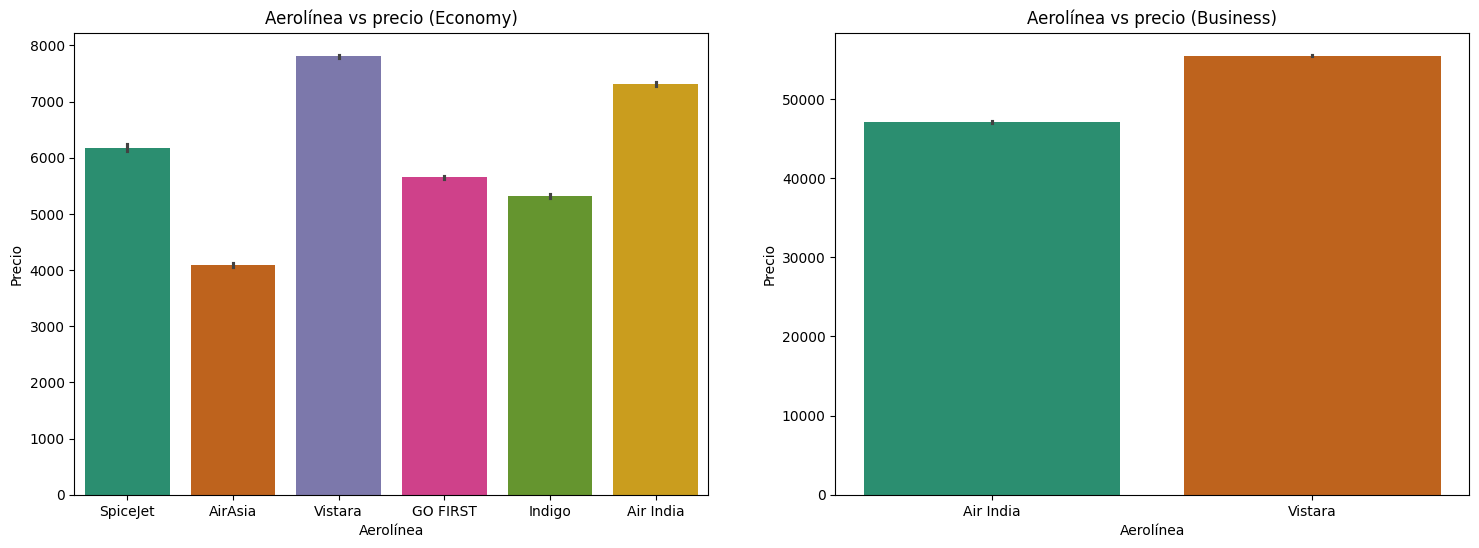

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

df['airline'] = df['airline'].replace({'Air_India':'Air India','GO_FIRST':'GO FIRST'})

df_economy = df[df['class'] == 'Economy']
df_business = df[df['class'] != 'Economy']

sns.barplot(
    x=df_economy['airline'],
    y=df_economy['Price'],
    hue=df_economy['airline'],
    palette='Dark2',
    ax=axes[0]
)
axes[0].set_title('Aerolínea vs precio (Economy)')
axes[0].set_xlabel('Aerolínea')
axes[0].set_ylabel('Precio')

sns.barplot(
    x=df_business['airline'],
    y=df_business['Price'],
    hue=df_business['airline'],
    palette='Dark2',
    ax=axes[1]
)
axes[1].set_title('Aerolínea vs precio (Business)')
axes[1].set_xlabel('Aerolínea')
axes[1].set_ylabel('Precio')

plt.plot()

# Para exportar el gráfico de barras
plt.savefig("barplot.png")